# Análise da biodegradabilidade de moléculas com algorítmos preditivos

**Disciplina:** Aprendizado de máquina

**Docente:** Daniel R. Cassar

**Discente e autor:** Leonardo Ramos Gomes da Silva

## Introdução

A ciência de materiais visa criar soluções com diferentes combinações de materiais para diversas problemáticas. Nesse contexto, uma análise de extrema importância na criação de novos compostos ou combinações dos já conhecidos, é entender se este material é biodegradável ou não - tanto para compreender as aplicações biológicas, quanto a forma de descarte desses materiais. Uma das grandes aplicações é a substituição do plástico, por exemplo, pois a dispersão desse e outros materiais não biodegradáveis na natureza pode acarretar inúmeras adversidades. 

Dessa forma, surge a necessidade de tornar mais eficiente o processo de desenvolver compostos biodegradáveis, sendo os modelos indutivos boas ferramentas para isso. O objetivo deste caderno é, então, a criação, discussão e análise de algorítmos que permitem induzir a característica de biodegradabilidade dos materiais, portanto é um problema de classificação binária. Para isso será utilizado o *dataset* da *UC Irvine Machine Learning Repository* [1] cujos atributos são características das moléculas e o target é se é prontamente biodegradável (RB) ou não protamente biodegradável (NRB).

Serão construídos pipelines de pré-processamento e classificação, tendo como algorítmos finais o *K*-Vizinhos Próximos, a Árvore de Decisão, a Floresta Aleatória, a Regressão Logística e Naive Baye Gaussiano, com validação cruzada inicial nesses pipelines. Por fim, cada pipeline terá seus hiperparâmetros otimizados pelo `optuna`, com validação cruzada ao final. Os resultados são mostrados em gráficos para fácil visualização, contendo o histórico de busca do optuna, a importância de cada hiperparâmetro na otimização de cada modelo, as matrizes de confusão, os boxplots e,como a principal métrica de desempenho dos modelos será a AP [2], por conta do desbalanceamento nos dados, a curva de precisão e *recall*. 

O caderno consta com uma seção final evidenciando as conclusões acerca do projeto e os principais aprendizados, dado que o caderno é uma tarefa da disciplina de Aprendizado de Máquina, tendo como docente o Professor Doutor Daniel R. Cassar, na Ilum - Escola de Ciências, curso de ensino superior do Centro de Pesquisa em Energia e Materiais (CNPEM).

## Fundamentação e justificativa dos modelos de previsão

Para escolher o melhor modelo de previsão a fim de analisar se as moléculas são ou não prontamente biodegradáveis, é necessário que haja a comparação entre modelos, com os hiperparâmetros otimizados, medindo seu desempenho ao final. Foram escolhidos cinco modelos para realizar a categorização binária. Nesta seção explico em qual hipótese se fundamenta cada modelo para entender seu funcionamento. Todas as informações foram tiradas da página de aprendizado supervisionado do *scikit* [3]

#### *K*-Vizinhos Próximos (*K-Nearest Neighbors* -- KNN)
O KNN é um algoritmo baseado na proximidade entre as amostras. Para classificar uma nova molécula, o modelo identifica as \(k\) amostras mais próximas no conjunto de treinamento, considerando uma medida de distância entre seus atributos. A classe prevista é determinada pela votação entre os vizinhos selecionados, podendo atribuir pesos diferentes de acordo com a distância. O algoritmo não constrói um modelo explícito durante o treinamento, pois utiliza diretamente os dados armazenados para realizar as previsões.

#### Árvore de Decisão
A Árvore de Decisão realiza classificações por meio de uma estrutura hierárquica de decisões. O algoritmo divide os dados com base nos atributos que melhor separam as classes, utilizando critérios como a entropia de Shannon. Cada nó representa uma condição sobre determinado atributo, enquanto as folhas representam as classes previstas. Sua principal vantagem é a facilidade de interpretação, pois permite visualizar as condições utilizadas para classificar uma molécula.

#### Floresta Aleatória
A Floresta Aleatória é um algoritmo de aprendizado supervisionado baseado na combinação de múltiplas árvores de decisão. Cada árvore é treinada utilizando diferentes amostras dos dados e subconjuntos aleatórios de atributos. Para realizar a classificação, o modelo combina as previsões das árvores por meio de votação majoritária, selecionando a classe mais frequentemente prevista. Essa abordagem reduz a variância e ajuda a evitar o sobreajuste (overfitting), proporcionando maior capacidade de generalização.

#### Regressão Logística
A Regressão Logística é um modelo de classificação que estima a probabilidade de uma amostra pertencer a determinada classe. Para isso, utiliza uma combinação linear dos atributos de entrada, transformada pela função logística, que produz valores entre 0 e 1. A classificação é realizada a partir de um limiar de decisão aplicado à probabilidade estimada. Apesar do nome, é utilizada para problemas de classificação, sendo especialmente adequada para classificações binárias.

#### Naive Bayes Gaussiano
O Naive Bayes Gaussiano é um algoritmo probabilístico fundamentado no teorema de Bayes. Sua principal hipótese é que os atributos são condicionalmente independentes entre si quando considerada uma determinada classe. Além disso, assume que os valores de cada atributo seguem uma distribuição normal (Gaussiana) dentro de cada classe. A partir dessas distribuições, o modelo calcula a probabilidade de uma molécula pertencer a cada categoria e seleciona aquela com maior probabilidade estimada. Vale ressaltar que mesmo que os atributos não sigam a Gaussiana, este modelo ainda consegue performar bem, sendo válido para a análise.

## Tratamento e análise 

Coletando os dados [1] com a biblioteca `pandas`. Os atributos do arquivo não vêm nomeados então foi criada uma lista com os atributos presentes no site para tornar o modelo mais interpretável.

In [1]:
import pandas as pd

nomes_colunas = ["SpMax_L", "J_Dz_e", "nHM", "F01_N_N", "F04_C_N", "NssssC", "nCb", "C_percent", "nCp", "nO", 
                "F03_C_N", "SdssC", "HyWi_B_m", "LOC", "SM6_L", "F03_C_O", "Me", "Mi", "nN_N", "nArNO2", 
                "nCRX3", "SpPosA_B_p", "nCIR", "B01_C_Br", "B03_C_Cl", "N_073", "SpMax_A", "Psi_i_1d", "B04_C_Br", 
                "SdO", "TI2_L", "nCrt", "C_026", "F02_C_N", "nHDon", "SpMax_B_m", "Psi_i_A", "nN", "SM6_B_m", 
                "nArCOOR", "nX", "class"]

df = pd.read_csv(
    "data/biodeg.csv",
    sep=";",
    header=None,
    names=nomes_colunas
)

print(f"Tamanho inicial do DataFrame: {df.shape[0]} linhas e {df.shape[1]} colunas")

df.head(5)

Tamanho inicial do DataFrame: 1055 linhas e 42 colunas


,SpMax_L,J_Dz_e,nHM,F01_N_N,F04_C_N,NssssC,nCb,C_percent,nCp,nO,...,C_026,F02_C_N,nHDon,SpMax_B_m,Psi_i_A,nN,SM6_B_m,nArCOOR,nX,class
0,3.919,2.6909,0,0,0,0,0,31.4,2,0,...,0,0,0,2.949,1.591,0,7.253,0,0,RB
1,4.170,2.1144,0,0,0,0,0,30.8,1,1,...,0,0,0,3.315,1.967,0,7.257,0,0,RB
2,3.932,3.2512,0,0,0,0,0,26.7,2,4,...,0,0,1,3.076,2.417,0,7.601,0,0,RB
3,3.000,2.7098,0,0,0,0,0,20.0,0,2,...,0,0,1,3.046,5.000,0,6.690,0,0,RB
4,4.236,3.3944,0,0,0,0,0,29.4,2,4,...,0,0,0,3.351,2.405,0,8.003,0,0,RB


Separação dos atributos e do alvo e definição do tamanho do teste que será utilizado, de 10%, por ter mais de 1000 exemplos o que proporciona uma boa quantidade para teste enquanto preserva bastante para o aprendizado. Além disso é utilizado o método `dropna()` para retirar valores vazios, mas percebe-se que o *dataset* não possui valores indisponíveis.

In [2]:
ATRIBUTOS = ["SpMax_L","J_Dz_e","nHM","F01_N_N","F04_C_N","NssssC","nCb","C_percent","nCp","nO","F03_C_N","SdssC",
             "HyWi_B_m","LOC","SM6_L","F03_C_O","Me","Mi","nN_N","nArNO2","nCRX3","SpPosA_B_p","nCIR","B01_C_Br",
             "B03_C_Cl","N_073","SpMax_A","Psi_i_1d","B04_C_Br","SdO","TI2_L","nCrt","C_026","F02_C_N","nHDon",
             "SpMax_B_m","Psi_i_A","nN","SM6_B_m","nArCOOR","nX"]

TARGET = ["class"]

TAMANHO_TESTE = 0.1
SEMENTE_ALEATORIA = 73701

df.dropna()

x = df.reindex(ATRIBUTOS, axis=1)
y = df.reindex(TARGET, axis=1)


print(f"Tamanho do DataFrame após dropna: {df.shape[0]} linhas e {df.shape[1]} colunas")

Tamanho do DataFrame após dropna: 1055 linhas e 42 colunas


Definindo a ordem das classes.

In [3]:
ordem_labels = df["class"].unique().tolist()

ordem_labels

['RB', 'NRB']

Anteriormente à separação de treino e teste, será feito um split agrupado para coibir possíveis vazamentos de dados. Para isso será criado um *dataset* cujos dados são arredondados para apenas uma casa decimal para retirar dados redundantes e quase redundantes, diferenciando o máximo possível. A escolha de uma casa decimal pois a maior parte dos atributos que recebem valores float possuem até 4 casas decimais, sendo 0.1 uma boa aproximação para caso estejam muito próximos. 

In [4]:
df_arredondada = df.round(decimals=1)

grupos = df_arredondada.groupby(ATRIBUTOS).ngroup()

print(f"Número de exemplos: {len(df)}")
print(f"Grupos únicos: {grupos.nunique()}")

df_arredondada

Número de exemplos: 1055
Grupos únicos: 1039


,SpMax_L,J_Dz_e,nHM,F01_N_N,F04_C_N,NssssC,nCb,C_percent,nCp,nO,...,C_026,F02_C_N,nHDon,SpMax_B_m,Psi_i_A,nN,SM6_B_m,nArCOOR,nX,class
0,3.9,2.7,0,0,0,0,0,31.4,2,0,...,0,0,0,2.9,1.6,0,7.3,0,0,RB
1,4.2,2.1,0,0,0,0,0,30.8,1,1,...,0,0,0,3.3,2.0,0,7.3,0,0,RB
2,3.9,3.3,0,0,0,0,0,26.7,2,4,...,0,0,1,3.1,2.4,0,7.6,0,0,RB
3,3.0,2.7,0,0,0,0,0,20.0,0,2,...,0,0,1,3.0,5.0,0,6.7,0,0,RB
4,4.2,3.4,0,0,0,0,0,29.4,2,4,...,0,0,0,3.4,2.4,0,8.0,0,0,RB
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1050,5.4,2.9,0,0,0,2,0,32.1,4,1,...,0,6,1,3.6,2.2,1,8.1,0,0,NRB
1051,5.3,3.4,0,0,9,0,0,35.3,0,9,...,0,3,0,3.8,3.1,3,9.3,0,0,NRB
1052,4.9,1.8,0,1,9,0,5,44.4,0,4,...,4,13,0,3.8,2.6,5,9.5,1,0,NRB
1053,5.2,1.7,2,0,36,0,9,56.1,0,0,...,1,16,0,5.8,2.1,8,11.1,0,1,NRB


O método utilizado para separação treino e teste será o `StratifiedGroupKFold` pois ele leva em conta o desbalanceamento do target ao realizar a separação e leva em conta os grupos únicos criados anteriormente para previnir vazamento dos dados.

In [5]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=SEMENTE_ALEATORIA
)

indices_treino, indices_teste = next(
    sgkf.split(x, y, groups=grupos)
)

df_treino = df.iloc[indices_treino]
df_teste = df.iloc[indices_teste]

x_treino = df_treino.reindex(ATRIBUTOS, axis=1).values
y_treino = df_treino.reindex(TARGET, axis=1).values.ravel()

x_teste = df_teste.reindex(ATRIBUTOS, axis=1).values
y_teste = df_teste.reindex(TARGET, axis=1).values.ravel()

x = df.reindex(ATRIBUTOS, axis=1).values
y = df.reindex(TARGET, axis=1).values.ravel()

Tamanho do conjunto de treino.

In [6]:
print(f"Tamanho do conjunto de treino: {x_treino.shape[0]} exemplos")

Tamanho do conjunto de treino: 949 exemplos


Tipos de dados presentes no *dataset*.

In [7]:
df.dtypes

SpMax_L       float64
J_Dz_e        float64
nHM             int64
F01_N_N         int64
F04_C_N         int64
NssssC          int64
nCb             int64
C_percent     float64
nCp             int64
nO              int64
F03_C_N         int64
SdssC         float64
HyWi_B_m      float64
LOC           float64
SM6_L         float64
F03_C_O         int64
Me            float64
Mi            float64
nN_N            int64
nArNO2          int64
nCRX3           int64
SpPosA_B_p    float64
nCIR            int64
B01_C_Br        int64
B03_C_Cl        int64
N_073           int64
SpMax_A       float64
Psi_i_1d      float64
B04_C_Br        int64
SdO           float64
TI2_L         float64
nCrt            int64
C_026           int64
F02_C_N         int64
nHDon           int64
SpMax_B_m     float64
Psi_i_A       float64
nN              int64
SM6_B_m       float64
nArCOOR         int64
nX              int64
class             str
dtype: object

Todos os atributos são numéricos, alguns são de ponto flutuante e outros inteiros.

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SpMax_L,1055.0,4.782644,0.546916,2.0000,4.48100,4.8280,5.12500,6.4960
J_Dz_e,1055.0,3.069508,0.831308,0.8039,2.50275,3.0463,3.43765,9.1775
nHM,1055.0,0.716588,1.462452,0.0000,0.00000,0.0000,1.00000,12.0000
F01_N_N,1055.0,0.042654,0.256010,0.0000,0.00000,0.0000,0.00000,3.0000
F04_C_N,1055.0,0.980095,2.332955,0.0000,0.00000,0.0000,1.00000,36.0000
NssssC,1055.0,0.290047,1.073771,0.0000,0.00000,0.0000,0.00000,13.0000
nCb,1055.0,1.646445,2.224822,0.0000,0.00000,1.0000,3.00000,18.0000
C_percent,1055.0,37.055640,9.144466,0.0000,30.45000,37.5000,43.40000,60.7000
nCp,1055.0,1.376303,1.963521,0.0000,0.00000,1.0000,2.00000,24.0000
nO,1055.0,1.803791,1.775435,0.0000,0.00000,2.0000,3.00000,12.0000


Visualização do balanceamento dos dados.

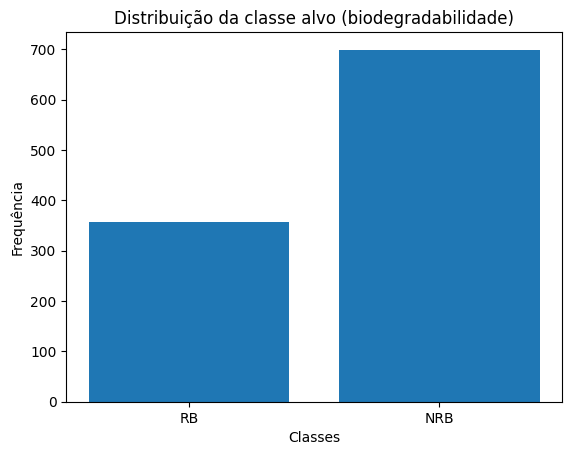

In [9]:
import matplotlib.pyplot as plt

distribuicao = [df.loc[df["class"] == "RB"].shape[0],
                df.loc[df["class"] == "NRB"].shape[0]]

plt.bar(range(len(distribuicao)), distribuicao)
plt.xlabel("Classes")
plt.ylabel("Frequência")
plt.title("Distribuição da classe alvo (biodegradabilidade)")
plt.xticks(range(len(distribuicao)), ["RB", "NRB"])
plt.show()

Percebe-se que os dados são desbalanceados, com aproximadamente 2/3 dos dados sendo da classe "NRB". Por conta do desbalanceamento, AP (Average Precision) será a principal métrica de avaliação, pois métricas como acurácia e ROC-AUC podem apresentar resultados excessivamente otimistas, uma vez que são fortemente influenciadas pela grande quantidade de exemplos da classe majoritária. Dessa forma, a AP fornece uma medida mais representativa da capacidade do modelo de detectar corretamente indivíduos da classe RB, informação mais valiosa visto que a procura atual é pela utilização de materiais que se degradam no meio ambiente. Para entender melhor como está a distribuição dos dados, o quadro abaixo, feito com a IA Claude, conta com gráficos de todos os atributos com os valores assumidos por cada atributo e a frequência desse. Além disso, está colorido em vermelho a frequência de moléculas com aquele valor que é não biodegradável e em verde a frequência das moléculas com o valor que são biodegradáveis.

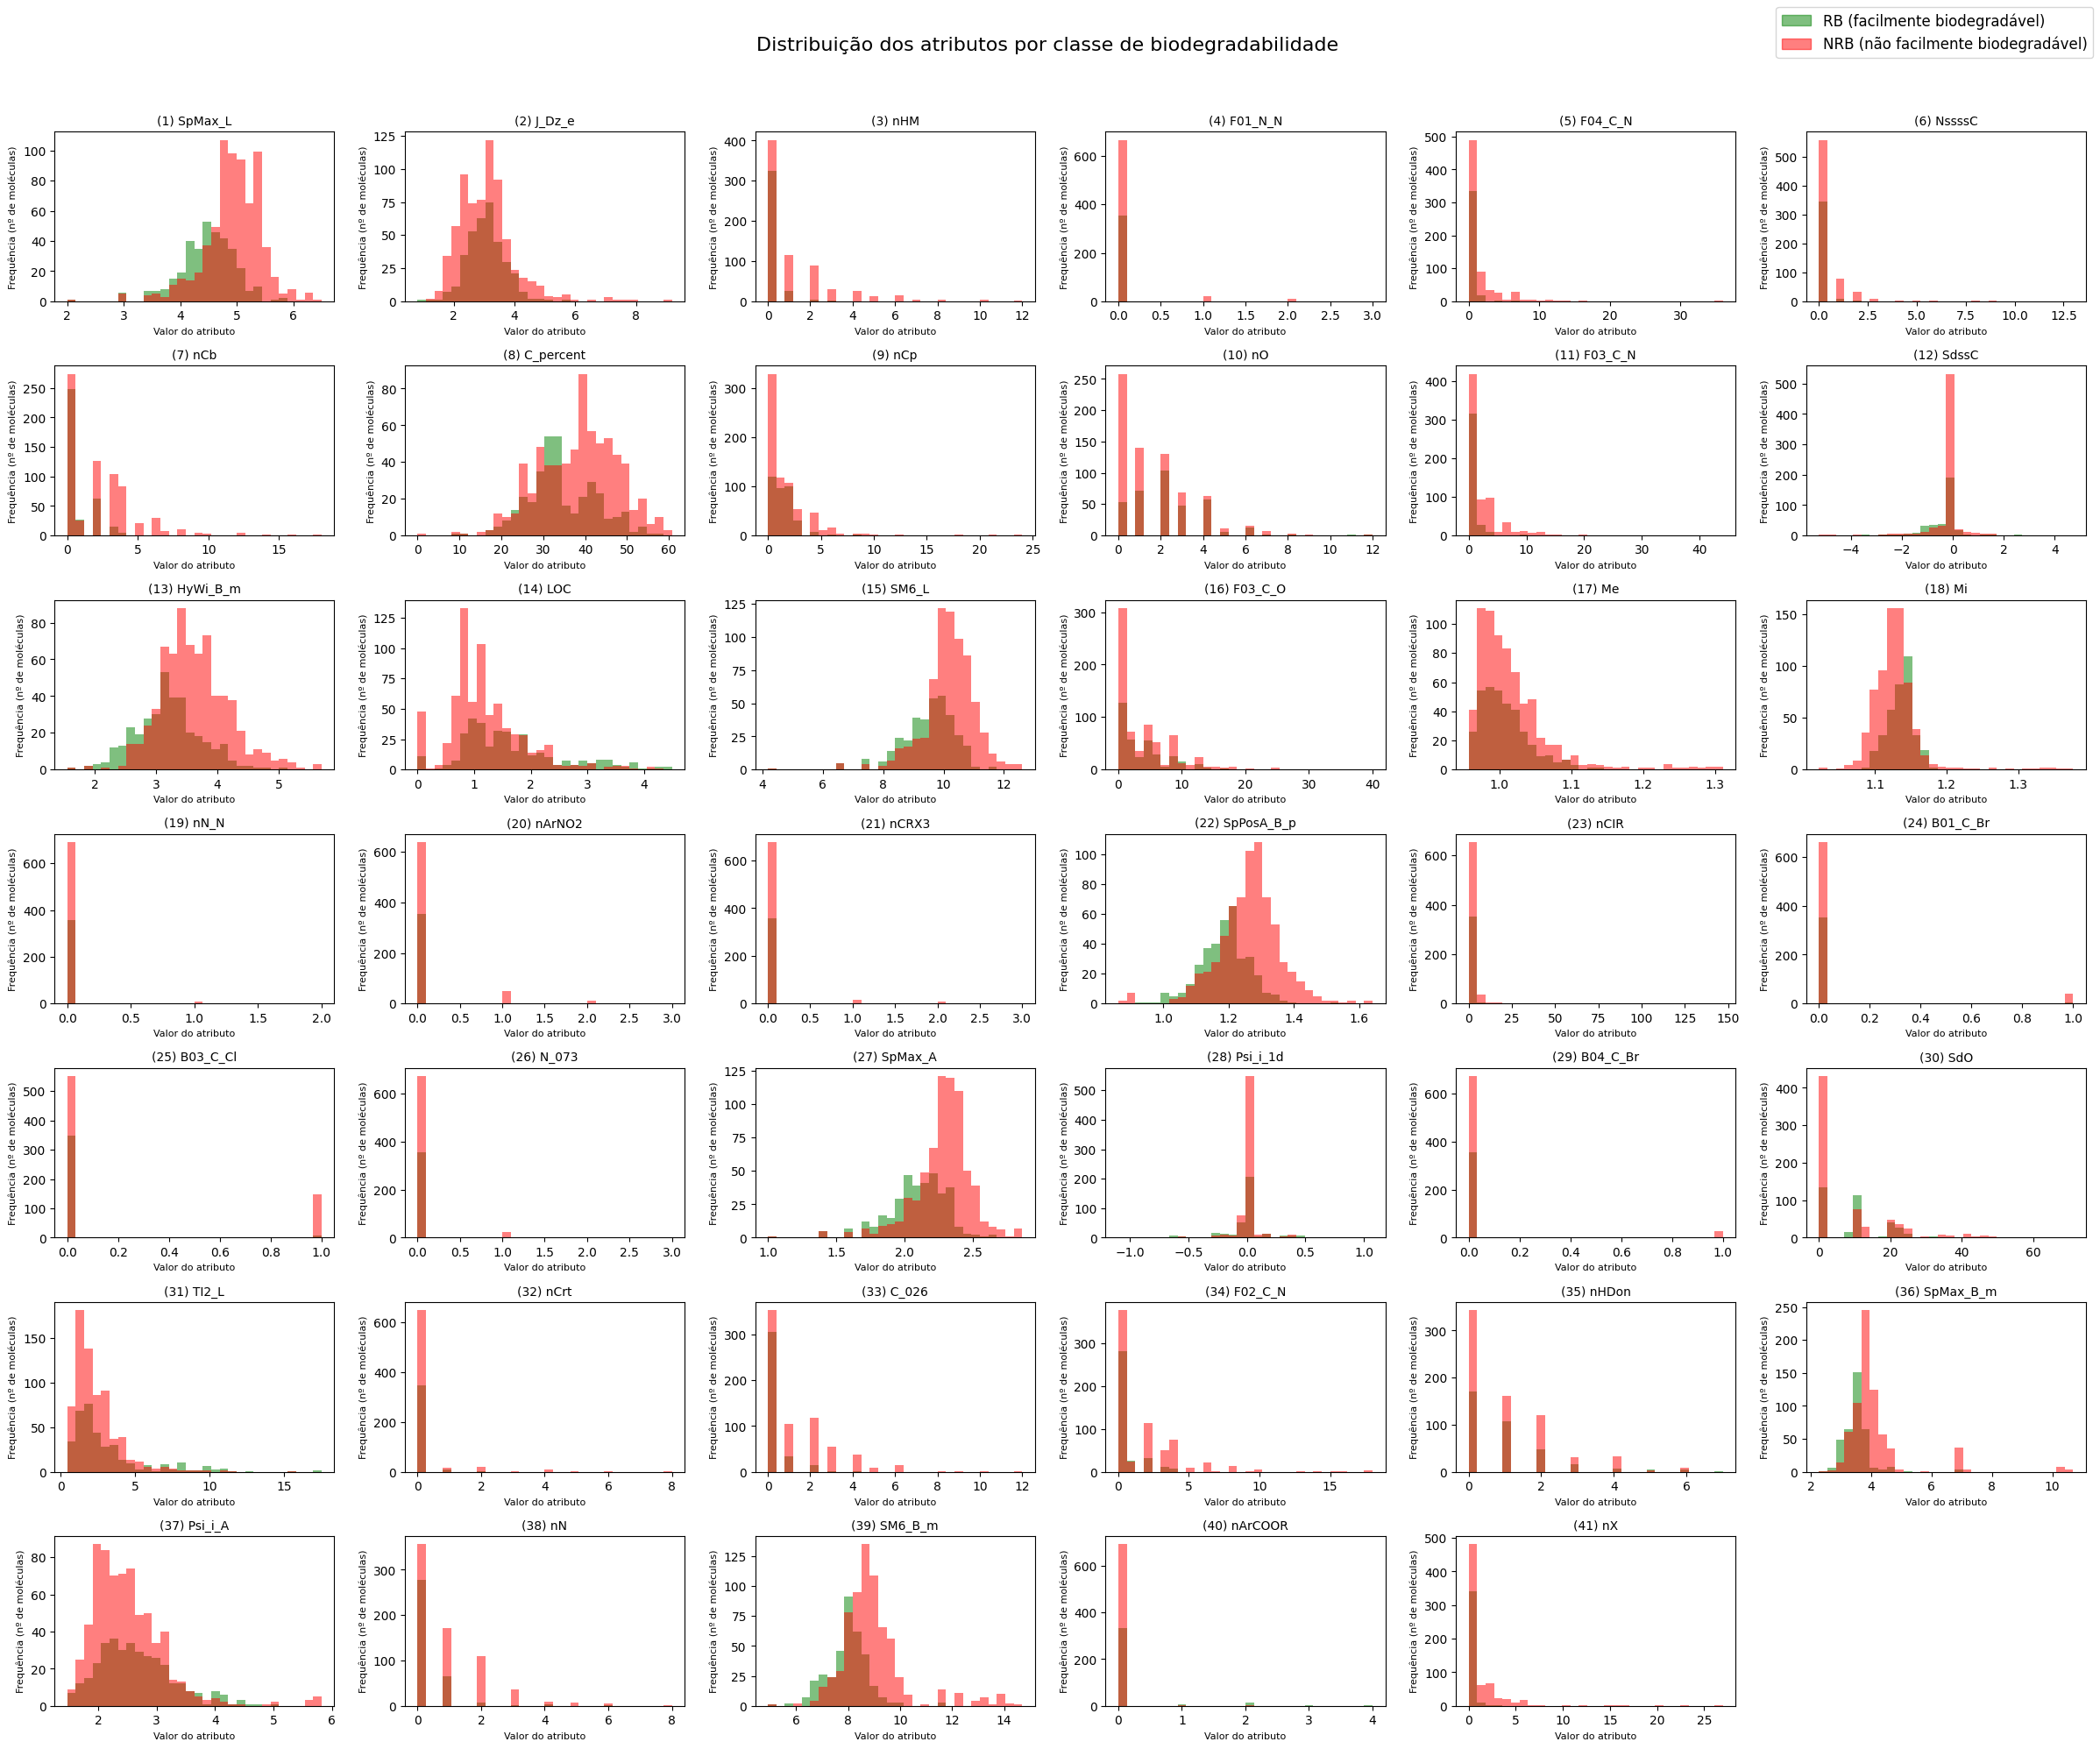

In [10]:
import numpy as np
from matplotlib.patches import Patch

col_classe = "class"
atributos = [c for c in df.columns if c != col_classe]
cores = {"RB": "green", "NRB": "red"}

n_cols = 6
n_rows = int(np.ceil(len(atributos) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(24, 20))
axes = axes.flatten()

for i, (ax, col) in enumerate(zip(axes, atributos), start=1):
    bins = np.histogram_bin_edges(df[col], bins=30)

    for classe, cor in cores.items():
        ax.hist(df.loc[df[col_classe] == classe, col], bins=bins, color=cor, alpha=0.5)

    ax.set_title(f"({i}) {col}", fontsize=10)
    ax.set_xlabel("Valor do atributo", fontsize=8)
    ax.set_ylabel("Frequência (nº de moléculas)", fontsize=8)

for ax in axes[len(atributos):]:
    ax.axis("off")

fig.legend(
    handles=[
        Patch(color="green", alpha=0.5, label="RB (facilmente biodegradável)"),
        Patch(color="red", alpha=0.5, label="NRB (não facilmente biodegradável)"),
    ],
    loc="upper right", fontsize=12
)

fig.suptitle("Distribuição dos atributos por classe de biodegradabilidade", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

Os gráficos demonstram o desbalanceamnento dos dados ao ficar evidente que os "NRB" ultrapassam sempre os "RB". Além disso, pode-se perceber também que em alguns gráficos, como em todos que são tipo Sp, há um deslocamento à direita por parte de da característica de não ser protamente biodegradável, que pode indicar uma leve separação nos dados. Apesar dessa leve separação visualizada, provavelmente não surtirá grande efeito no desempenho dos modelos por não estar presente na maioria dos atributos. As informações serão discutidas ao final após todo o processo de otimização e processamento.

Sobre as diferentes escalas em que se encontram os diferentes atributos, infere-se que normalizadores serão importantes para um bom desempenho dos modelos, especialmente o KNN, o qual é mais sensível a dados que estejam em menor escala.

## Baseline

Para criar a base de análise e comparação, será criado abaixo o modelo **baseline**, modelo de previsão que, no caso de categorização, leva em conta apenas a moda do *target*. O metodo utilizado é o `DummyClassifier()`do `scikit` em um `Pipeline` que só será visto adiante na seção seguinte, com sua performance.

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

modelo_baseline_pipeline = Pipeline([("clf", DummyClassifier(strategy="most_frequent"))])
modelo_baseline_pipeline.fit(x_treino, y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['NRB','RB']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,41
,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=No

O modelo baseline não performou bem em acurácia, média macro e média ponderada, conseguindo, como esperado de acurácia o equivalente a 2/3. A métrica de f1 ficou bem alta para o *baseline* em relação a "NRB", demonstrando não ser a melhor métrica para o problema desenvolvido neste caderno.

## Pipeline de modelagem

Antes de realizar a otimização de hiperparâmetros, vale analisar como cada modelo performará com os hiperparâmetros padrão, criado com pipeline, e será feita então uma validação cruzada desses modelos iniciais, antes do optuna. Os modelos são o de *k*-vizinhos próximos (KNN), regressor logístico, árvore de decisão, floresta aleatória e naive bayes gaussiano. Como quinto modelo de previsão, havia dúvida entre GaussNB e BernoulliNB, sendo o segundo rejeitado porque analisa os dados como binários, o que perderia bastante informação ao analisar as características moleculares que não são binárias, vistas no início do caderno.



### Funções

Abaixo é rodado o pipeline de de `KNeighborsClassifier` com o número de vizinhos *k* = 3, valor padrão desse modelo. Para criar os modelos com pipeline foi utilizada a função `Pipeline`, utilizando técnica de redução de dimensionalidade de `PCA` (Análise das Componentes Principais, do inglês) [4] com número de componentes 80% pois reduz a dimensionalidade ainda preservando grande parte da originalidade dos dados. Para melhor desempenho do modelo os dados serão normalizados com o normalizador padrão `StandartScaler`. Este normalizador também será aplicado a todos os modelos por conta da diferença de escalas e amplitudes presente nas definições de diversas características das moléculas.

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA


NUM_VIZINHOS = 3
N_COMPONENTES = 0.8

modelo_knn_pipeline = Pipeline([("scaler", StandardScaler()),
          ("reducer", PCA(n_components=N_COMPONENTES, svd_solver="full")),
          ("clf", KNeighborsClassifier(n_neighbors=NUM_VIZINHOS))])
          
modelo_knn_pipeline.fit(x_treino, y_treino);

Abaixo é rodado o pipeline de `LogisticRegression`.

In [13]:
from sklearn.linear_model import LogisticRegression


modelo_logreg_pipeline = Pipeline([("scaler", StandardScaler()),
          ("reducer", PCA(n_components= N_COMPONENTES)),
          ("clf", LogisticRegression(max_iter=1000, random_state=SEMENTE_ALEATORIA))])

modelo_logreg_pipeline.fit(x_treino, y_treino);

Abaixo é rodado o pipeline de `DecisionTreeClassifier`. 

In [14]:
from sklearn.tree import DecisionTreeClassifier


modelo_arvore_pipeline = Pipeline([
        ("reducer", PCA(n_components= N_COMPONENTES)),
        ("clf", DecisionTreeClassifier(random_state=SEMENTE_ALEATORIA)),
    ])

modelo_arvore_pipeline.fit(x_treino, y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('reducer', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['NRB','RB']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,41
,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",0.8
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as ma

Abaixo é rodado o pipeline de `RandomForestClassifier`. O hiperparâmetro de *bootstrap* (amostragem com reposição) está como verdadeiro pois este garante diminuição na variância do modelo, sendo avaliado como importante ao utilizar este modelo.

In [15]:
from sklearn.ensemble import RandomForestClassifier


modelo_floresta_pipeline = Pipeline([
        ("reducer", PCA(n_components= N_COMPONENTES)),
        ("clf", RandomForestClassifier(bootstrap=True, random_state=SEMENTE_ALEATORIA)),
    ])

modelo_floresta_pipeline.fit(x_treino, y_treino);

Abaixo é rodado o pipeline de `BernoulliNB`.

In [16]:
from sklearn.naive_bayes import GaussianNB

modelo_gaussianNB_pipeline = Pipeline([
        ("reducer", PCA(n_components= N_COMPONENTES)),
        ("clf", GaussianNB()),
    ])

modelo_gaussianNB_pipeline.fit(x_treino, y_treino);

Dicionário com a associação entre os nomes dos modelos e os modelos criados, para facilitar a computação dos dados na validação cruzada.

In [17]:
CONSTRUTORES = {
    "Baseline": modelo_baseline_pipeline,
    "KNN": modelo_knn_pipeline,
    "Regressão logística": modelo_logreg_pipeline,
    "Árvore de decisão": modelo_arvore_pipeline,
    "Floresta aleatória": modelo_floresta_pipeline,
    "Naive Bayes": modelo_gaussianNB_pipeline,
}

### Validação cruzada inicial

A validação cruzada é utilizada para diminuir o efeito do acaso. Nesse caso, utilizaremos então a função `cross_val_score` para realizar a validação cruzada e `make_scorer` para criar uma função com a métrica utilizada de `average_precision_score`. Para realizar essa validação, o parâmetro cv (estratégia de partição dos dados) está recebendo o `StratifiedGroupKFold` que leva em conta a proporção do target e os grupos similares para evitar vazamento de dados.

In [18]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, average_precision_score

grupos_treino = grupos.iloc[indices_treino]

ap = make_scorer(average_precision_score, response_method="predict_proba", pos_label="RB")

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE_ALEATORIA)

resultados = {}
for nome, modelo in CONSTRUTORES.items():
    s = cross_val_score(modelo, x_treino, y_treino, groups=grupos_treino, cv=cv, scoring=ap, n_jobs=-1)
    resultados[nome] = {"AP (média)": s.mean(), "Desvio": s.std()}

df_resultados_sem_otimizacao = pd.DataFrame(resultados).T.sort_values("AP (média)", ascending=False)

df_resultados_sem_otimizacao

,AP (média),Desvio
Regressão logística,0.808246,0.037013
KNN,0.752907,0.030566
Floresta aleatória,0.697718,0.069773
Naive Bayes,0.536429,0.029114
Árvore de decisão,0.462553,0.018740
Baseline,0.337202,0.001328


A Regressão Logística foi que melhor performou na métrica utilizada, com um bom razoável, com um desvio padrão mediano. Com essa análise dos pipelines de cada modelo com os hiperparâmetros padrão de cada, o modelo a ser escolhido seria a Regressão Logística, que conseguiu superar, muito bem inclusive, a Floresta Aleatória. Interessante notar que o modelo de *k*-vizinhos próximos performou melhor também que a Floresta Aleatória, que provavelmente indica que o modelo está muito mal otimizado. Segue-se com a otimização na seção seguinte.

## Otimização de hipeparâmetros com optuna

Importando a biblioteca `optuna` responsável pela otimização de hiperparâmetros. O comando utilizado na célula abaixo serve para não tornar a análise do optuna tão espaçosa. O target utilizado para treino será transformado em binário, levando em consideração o *prontamente biodegradável* como 1 e o *não prontamente biodegradável* como 0, por conta da métrica de desempenho utilizada, que realiza a análise em dados binários 0 e 1, o que facilita a busca do optuna (guiada pelo desempenho de cada trial).

In [19]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

y_treino_bin = (y_treino == "RB").astype(int)

### Justificativa dos hiperparâmetros e intervalos

A fim de compreender os hiperparâmetros utilizados e justificar seus intervalos, foi criada uma tabela que dispõe mais legível e organizadamente as informações. Dados os intervalos e as justificativas, a tabela em markdown foi construída pela IA ChatGPT.

#### K-Vizinhos Mais Próximos

| Hiperparâmetro | Intervalo | Escala | Justificativa |
|---|---|---|---|
| `n_neighbors` | 1 a 800 | Logarítmica | Determina a quantidade de vizinhos utilizados para classificação. O intervalo amplo permite avaliar desde classificações muito locais, influenciadas por poucos vizinhos, até classificações mais generalizadas. A escala logarítmica favorece a exploração de valores menores de k, nos quais pequenas alterações podem produzir diferenças relevantes no resultado. |
| `weights` | `uniform`, `distance` | Categórica | Define como os vizinhos contribuem para a classificação. A opção `uniform` atribui o mesmo peso a todos, enquanto `distance` concede maior influência aos vizinhos mais próximos. A comparação permite verificar se a proximidade das moléculas é mais relevante do que a contribuição uniforme dos vizinhos. |
| `metric` | `euclidean`, `manhattan`, `minkowski` | Categórica | Define a métrica utilizada para calcular a distância entre as observações. A distância euclidiana considera a distância geométrica direta, enquanto a Manhattan soma as diferenças absolutas entre os atributos. A métrica Minkowski generaliza essas duas possibilidades, permitindo avaliar diferentes formas de representar a proximidade entre moléculas. |

#### Regressão Logística

| Hiperparâmetro | Intervalo | Escala | Justificativa |
|---|---|---|---|
| `C` | 0,001 a 1000 | Logarítmica | Controla o inverso da intensidade da regularização: valores menores produzem maior penalização dos coeficientes, enquanto valores maiores permitem maior liberdade ao modelo. O intervalo amplo, distribuído logaritmicamente, permite investigar desde modelos fortemente regularizados até modelos com regularização reduzida, avaliando o equilíbrio entre ajuste e generalização. |
| `penalty` | `l1`, `l2` | Categórica | Define o tipo de regularização aplicado aos coeficientes. A regularização L1 pode reduzir determinados coeficientes a zero, favorecendo a seleção de atributos, enquanto a L2 penaliza coeficientes elevados sem necessariamente eliminá-los. A comparação permite avaliar diferentes estratégias de controle da complexidade do modelo. |
| `solver` | `liblinear`, `saga` | Categórica | Define o algoritmo utilizado para otimizar os coeficientes da regressão logística. Ambos são compatíveis com as regularizações L1 e L2, mas apresentam estratégias de otimização distintas. A comparação permite avaliar qual abordagem apresenta melhor desempenho para o conjunto de dados. |
| `class_weight` | `None`, `balanced` | Categórica | Define se as classes receberão pesos iguais ou pesos inversamente proporcionais às suas frequências. A inclusão de `balanced` permite avaliar se a compensação de possíveis desproporções entre as classes melhora a identificação das moléculas prontamente biodegradáveis. |

#### Árvore de Decisão

| Hiperparâmetro | Intervalo | Escala | Justificativa |
|---|---|---|---|
| `criterion` | `gini`, `entropy`, `log_loss` | Categórica | Define o critério utilizado para avaliar a qualidade das divisões dos nós. A comparação entre os critérios permite investigar diferentes formas de medir a impureza das classes e identificar qual produz divisões mais adequadas para distinguir as moléculas biodegradáveis e não biodegradáveis. |
| `splitter` | `best`, `random` | Categórica | Determina a estratégia utilizada para selecionar as divisões dos nós. A opção `best` seleciona a melhor divisão encontrada, enquanto `random` considera divisões aleatórias. A comparação permite avaliar se a seleção determinística ou a introdução de aleatoriedade favorece a generalização do modelo. |
| `max_depth` | 2 a 300 | Linear | Estabelece a profundidade máxima da árvore. O limite inferior evita árvores extremamente simples, enquanto o superior permite investigar estruturas mais complexas. Esse intervalo possibilita avaliar o equilíbrio entre a capacidade de aprendizado dos padrões moleculares e o risco de sobreajuste. |
| `min_samples_split` | 2 a 30 | Linear | Define o número mínimo de amostras necessário para permitir a divisão de um nó. O limite inferior permite divisões com poucas observações, enquanto valores maiores restringem a expansão da árvore. O intervalo possibilita avaliar diferentes níveis de complexidade e controle do sobreajuste. |
| `min_samples_leaf` | 1 a 20 | Linear | Determina o número mínimo de amostras que uma folha deve conter. O limite inferior permite folhas com apenas uma observação, enquanto valores maiores exigem agrupamentos mais representativos. O intervalo permite investigar o efeito da suavização das decisões e da redução de divisões excessivamente específicas. |
| `max_features` | `None`, `sqrt`, `log2` | Categórica | Define a quantidade de atributos considerados na busca pela melhor divisão. `None` permite utilizar todos os atributos, enquanto `sqrt` e `log2` restringem a quantidade considerada. A comparação permite avaliar se a utilização de todos os descritores ou de subconjuntos deles favorece a construção da árvore. |
| `max_leaf_nodes` | 10 a 800 | Logarítmica | Estabelece o número máximo de folhas da árvore. O limite inferior restringe a complexidade estrutural, enquanto o superior permite estruturas mais detalhadas. O intervalo possibilita avaliar diferentes capacidades de representação dos padrões presentes nos descritores moleculares. A escala logarítmica favorece a exploração de valores menores para o hiperparâmetro. |
| `min_impurity_decrease` | 0 a 0,1 | Linear | Define a redução mínima de impureza necessária para que uma divisão seja realizada. O valor zero permite todas as divisões que produzam alguma redução de impureza, enquanto valores maiores exigem melhorias mais expressivas. O intervalo permite avaliar diferentes níveis de exigência para a criação de novos nós. |

#### Floresta Aleatória

| Hiperparâmetro | Intervalo | Escala | Justificativa |
|---|---|---|---|
| `n_estimators` | 100 a 2000 | Logarítmica | Define a quantidade de árvores utilizadas na composição da floresta. O limite inferior permite avaliar conjuntos menores de árvores, enquanto o superior possibilita investigar modelos mais robustos e estáveis. A escala logarítmica permite explorar diferentes quantidades sem concentrar excessivamente a busca nos valores mais elevados, considerando também o custo computacional. |
| `criterion` | `gini`, `entropy`, `log_loss` | Categórica | Define o critério utilizado para avaliar a qualidade das divisões dos nós de cada árvore. A comparação permite investigar diferentes formas de medir a impureza e verificar qual favorece a separação das classes de biodegradabilidade. |
| `max_depth` | 5 a 800 | Linear | Estabelece a profundidade máxima de cada árvore. O limite inferior evita estruturas excessivamente simples, enquanto o superior permite investigar árvores mais complexas. O intervalo possibilita avaliar o equilíbrio entre a capacidade de identificar padrões moleculares e o risco de sobreajuste. |
| `min_samples_split` | 2 a 30 | Linear | Define o número mínimo de amostras necessário para dividir um nó. Valores menores permitem árvores mais detalhadas, enquanto valores maiores restringem a criação de novas ramificações. O intervalo permite avaliar diferentes níveis de complexidade das árvores que compõem a floresta. |
| `min_samples_leaf` | 1 a 20 | Linear | Determina o número mínimo de amostras em cada folha. Valores menores permitem decisões mais específicas, enquanto valores maiores exigem agrupamentos mais representativos. O intervalo permite investigar o efeito da suavização das decisões e da redução do sobreajuste. |
| `max_features` | 0,1 a 1,0 | Linear | Define a proporção de atributos considerados em cada divisão das árvores. O limite inferior permite maior restrição na seleção de descritores, enquanto o superior permite considerar todos os atributos disponíveis. O intervalo possibilita avaliar como diferentes níveis de aleatoriedade influenciam a diversidade entre as árvores e o desempenho da floresta. |
| `class_weight` | `None`, `balanced` | Categórica | Define se as classes receberão pesos iguais ou pesos inversamente proporcionais às suas frequências. A comparação permite avaliar se a compensação de possíveis desproporções entre as classes favorece a identificação das moléculas prontamente biodegradáveis. |
| `max_samples` | 0,3 a 1,0 | Linear | Determina a proporção de amostras utilizadas no treinamento de cada árvore, considerando a amostragem com reposição habilitada por `bootstrap=True`. O limite inferior permite avaliar árvores treinadas com subconjuntos menores, enquanto o superior permite utilizar toda a amostra de treinamento. O intervalo possibilita investigar como diferentes níveis de amostragem influenciam a diversidade e a generalização da floresta. |

#### Naive Bayes Gaussiano

| Hiperparâmetro | Intervalo | Escala | Justificativa |
|---|---|---|---|
| `var_smoothing` | $10^{-12}$ a $10^{-6}$ | Logarítmica | Controla a adição de uma pequena parcela da maior variância global dos atributos às variâncias individuais estimadas pelo modelo, proporcionando estabilidade numérica. O intervalo abrange diferentes intensidades de suavização, desde alterações muito pequenas até intervenções mais expressivas nas variâncias. A escala logarítmica permite explorar valores em diferentes ordens de magnitude, uma vez que esse parâmetro geralmente apresenta maior sensibilidade a variações relativas do que absolutas. |

### Funções do optuna

As funções abaixo foram retiradas e alteradas do material do Professor Daniel R. Cassar [5].

A função `sugere_pca` abaixo serve para fazer a otimização do PCA em todos os modelos ao ajustar o pipeline no optuna.

In [20]:
def sugere_pca(trial):
    if trial.suggest_categorical("usar_pca", [True, False]):
        return PCA(n_components=trial.suggest_float("variancia_pca", 0.70, 0.99),
                   svd_solver="full")
    return "passthrough"

As funções `cria_instancia_` abaixo criam uma instância em optuna com a variação dos hiperparâmetros discutidos anteriormente e retornam o pipeline do modelo para ser utilizado adiante.

In [21]:
# INSTÂNCIA KNN

def cria_instancia_KNN(trial):
    """Cria uma instância do modelo.
    Args:
      trial: objeto tipo Trial do optuna.
    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "n_neighbors": trial.suggest_int("num_vizinhos", 1, 800, log=True),
        "weights": trial.suggest_categorical("peso", ["uniform", "distance"]),
        "metric": trial.suggest_categorical("métrica", ["euclidean", "manhattan", "minkowski"]),
        # argumentos fixos
        "n_jobs": -1,   
    }
        
    modelo = KNeighborsClassifier(**parametros)

    return Pipeline([("scaler", StandardScaler()), ("pca", sugere_pca(trial)), ("classifier", modelo)])

# INSTÂNCIA REGRESSÃO LOGÍSTICA
    
def cria_instancia_LogReg(trial):
    """Cria uma instância do modelo.
    Args:
      trial: objeto tipo Trial do optuna.
    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "C": trial.suggest_float("C", 0.001, 1000, log=True),
        "penalty": trial.suggest_categorical("penalty", ["l1", "l2"]),
        "solver": trial.suggest_categorical("solver", ["liblinear", "saga"]),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        "max_iter": 5000,
        # argumentos fixos
        "n_jobs": -1,
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = LogisticRegression(**parametros)

    return Pipeline([("scaler", StandardScaler()), ("pca", sugere_pca(trial)), ("classifier", modelo)])

# INSTÂNCIA ÁRVORE ALEATÓRIA

def cria_instancia_arvore(trial):
    """Cria uma instância do modelo.
    Args:
      trial: objeto tipo Trial do optuna.
    Returns:
      Uma instância do modelo desejado.
    """


    parametros = {
        # espaço de busca
        "criterion": trial.suggest_categorical("critério", ["gini", "entropy", "log_loss"]),
        "splitter": trial.suggest_categorical("estrategia_divisao", ["best", "random"]),
        "max_depth": trial.suggest_int("profundidade_max", 2, 300),
        "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 20),
        "max_features": trial.suggest_categorical("max_atributos", [None, "sqrt", "log2"]),
        "max_leaf_nodes": trial.suggest_int("max_nos_folha", 10, 800, log=True),
        "min_impurity_decrease": trial.suggest_float("reducao_impureza_min", 0.0, 0.1),
        # não recebe n_jobs ou random_state

    }

    modelo = DecisionTreeClassifier(**parametros)

    return Pipeline([("scaler", StandardScaler()), ("pca", sugere_pca(trial)), ("classifier", modelo)])

# INSTÂNCIA FLORESTA ALEATÓRIA

def cria_instancia_floresta(trial):
    """Cria uma instância do modelo.
    Args:
      trial: objeto tipo Trial do optuna.
    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "n_estimators": trial.suggest_int("num_arvores", 100, 2000, log=True),
        "criterion": trial.suggest_categorical("critério", ["gini", "entropy", "log_loss"]),
        "max_depth": trial.suggest_int("profundidade_max", 5, 800),
        "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 20),
        "max_features": trial.suggest_float("num_max_atributos", 0.1, 1.0),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        "max_samples": trial.suggest_float("fracao_amostras", 0.3, 1.0),
        # argumentos fixos
        "bootstrap": True,
        "n_jobs": -1,
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = RandomForestClassifier(**parametros)

    return Pipeline([("scaler", StandardScaler()), ("pca", sugere_pca(trial)), ("classifier", modelo)])

# INSTÂNCIA GAUSSNB

def cria_instancia_gaussNB(trial):
    """Cria uma instância do modelo.
    Args:
      trial: objeto tipo Trial do optuna.
    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "var_smoothing": trial.suggest_float("suavizacao_variancia", 1e-12, 1e-6, log=True),
        # não recebe n_jobs ou random_state
    }

    modelo = GaussianNB(**parametros)

    return Pipeline([("scaler", StandardScaler()), ("pca", sugere_pca(trial)), ("classifier", modelo)])

Dicionário para não reescrever a função objetivo repetidamente.

In [22]:
INSTANCIAS = {
    "KNN": cria_instancia_KNN,
    "Regressão logística": cria_instancia_LogReg,
    "Árvore de decisão": cria_instancia_arvore,
    "Floresta aleatória": cria_instancia_floresta,
    "Naive Bayes Gaussiano": cria_instancia_gaussNB,
}

A `funcao_objetivo` tem como função computar a métrica de desempenho. Neste caso, a métrica de interesse é o *average precision* obtido por validação cruzada. 

In [23]:
def funcao_objetivo(trial, X, y, instancia, grupos):
    """Função objetivo do optuna

    Referencia:
      https://medium.com/@walter_sperat/ using-optuna-with-sklearn-the-right-way-part-1-6b4ad0ab2451
    """

    modelo = INSTANCIAS[instancia](trial)
    
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE_ALEATORIA)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        scoring="average_precision",
        cv=cv,
        groups=grupos
    )

    return metricas.mean()

O número de tentativas definido é o número de trials que será utilizado em todas as otimizações.

In [24]:
NUM_TENTATIVAS = 100

Importando as funções `create_study`, que cria o estudo do caso que vamos estudar, e `TPESampler`, que associa uma semente aleatória para reprodutibilidade.

In [25]:
from optuna import create_study
from optuna.samplers import TPESampler
sampler = TPESampler(seed=SEMENTE_ALEATORIA)

### *K*-vizinhos Próximos

A otimização é realizada em um objeto de estudo, que será definido para cada caso. A `funcao_objetivo_parcial`, com o método `partial` serve para efetivamente rodar o otimizador. O objeto de estudo de KNN é criado abaixo.


In [26]:
from functools import partial

sampler = TPESampler(seed=SEMENTE_ALEATORIA)

NOME_DO_ESTUDO = "biodegradabilidade_knn"

objeto_de_estudo_knn = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=sampler
)

funcao_objetivo_parcial = partial(
    funcao_objetivo, X=x_treino, y=y_treino_bin, instancia="KNN", grupos=grupos_treino
)

A otimização é rodada na célula abaixo e há visualização por meio de um DataFrame.

In [27]:
objeto_de_estudo_knn.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

df = objeto_de_estudo_knn.trials_dataframe()

df.head(5)

,number,value,datetime_start,datetime_complete,duration,params_métrica,params_num_vizinhos,params_peso,params_usar_pca,params_variancia_pca,system_attrs_tpe:relative_params:0,state
0,0,NaN,2026-11-08 11:54:13.896969,2026-11-08 11:54:14.372495,0 days 00:00:00.475526,euclidean,131.0,uniform,True,0.882860,NaN,FAIL
1,1,NaN,2026-11-08 12:04:03.483800,2026-11-08 12:04:03.530925,0 days 00:00:00.047125,NaN,NaN,NaN,NaN,NaN,NaN,FAIL
2,2,0.786330,2026-11-08 12:05:11.342167,2026-11-08 12:05:14.410181,0 days 00:00:03.068014,euclidean,131.0,uniform,True,0.882860,NaN,COMPLETE
3,3,0.735392,2026-11-08 12:05:14.436452,2026-11-08 12:05:14.679934,0 days 00:00:00.243482,manhattan,2.0,uniform,False,NaN,NaN,COMPLETE
4,4,0.831613,2026-11-08 12:05:14.703458,2026-11-08 12:05:15.097705,0 days 00:00:00.394247,minkowski,112.0,distance,True,0.868265,NaN,COMPLETE


Descrição de qual foi o maior AP encontrado, sua posição e seus hiperparâmetros.

In [28]:
melhor_trial = objeto_de_estudo_knn.best_trial

print(f"Melhor valor da função objetivo: {melhor_trial.value}")
print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

Melhor valor da função objetivo: 0.8621887371694745
Número do melhor trial: 84
Parâmetros do melhor trial: {'num_vizinhos': 38, 'peso': 'distance', 'métrica': 'manhattan', 'usar_pca': False}


Gráfico com visualização do histórico de otimização do optuna para o modelo KNN.

In [29]:
import optuna.visualization as vis

vis.plot_optimization_history(objeto_de_estudo_knn)

### Regressão Logística

O objeto de estudo de Regressão Logística é criado abaixo.

In [30]:
NOME_DO_ESTUDO = "biodegradabilidade_regressão"

objeto_de_estudo_logreg = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=sampler
)

funcao_objetivo_parcial = partial(
    funcao_objetivo, X=x_treino, y=y_treino_bin, instancia="Regressão logística", grupos=grupos_treino
)

A otimização é rodada na célula abaixo e há visualização por meio de um DataFrame.

In [31]:
objeto_de_estudo_logreg.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

df = objeto_de_estudo_logreg.trials_dataframe()

df.head(5)

C:\Users\leonardo2610065\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\leonardo2610065\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\leonardo2610065\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this wa

,number,value,datetime_start,datetime_complete,duration,params_C,params_class_weight,params_penalty,params_solver,params_usar_pca,params_variancia_pca,system_attrs_tpe:relative_params:0,state
0,0,0.852010,2026-11-08 12:05:58.708779,2026-11-08 12:05:59.032327,0 days 00:00:00.323548,0.046838,NaN,l2,liblinear,False,NaN,NaN,COMPLETE
1,1,0.822981,2026-11-08 12:05:59.074587,2026-11-08 12:05:59.374736,0 days 00:00:00.300149,3.401107,NaN,l1,liblinear,True,0.832644,NaN,COMPLETE
2,2,0.866863,2026-11-08 12:05:59.416015,2026-11-08 12:06:02.030831,0 days 00:00:02.614816,20.675125,NaN,l2,saga,False,NaN,NaN,COMPLETE
3,3,0.822781,2026-11-08 12:06:02.052296,2026-11-08 12:06:02.543674,0 days 00:00:00.491378,2.228280,NaN,l1,saga,True,0.830942,NaN,COMPLETE
4,4,0.805155,2026-11-08 12:06:02.583131,2026-11-08 12:06:02.885836,0 days 00:00:00.302705,6.018462,NaN,l2,liblinear,True,0.782945,NaN,COMPLETE


Descrição de qual foi o maior AP encontrado, sua posição e seus hiperparâmetros.

In [32]:
melhor_trial = objeto_de_estudo_logreg.best_trial

print(f"Melhor valor da função objetivo: {melhor_trial.value}")
print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

Melhor valor da função objetivo: 0.8716901324838909
Número do melhor trial: 81
Parâmetros do melhor trial: {'C': 1.6771674305875806, 'penalty': 'l1', 'solver': 'saga', 'class_weight': None, 'usar_pca': False}


Gráfico com visualização do histórico de otimização do optuna para o modelo Regressão Logística.

In [33]:
vis.plot_optimization_history(objeto_de_estudo_logreg)

### Árvore de Decisão

O objeto de estudo de Árvore de Decisão é criado abaixo.

In [35]:
sampler = TPESampler(seed=SEMENTE_ALEATORIA)

NOME_DO_ESTUDO = "biodegradabilidade_arvore"

objeto_de_estudo_arvore = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=sampler
)

funcao_objetivo_parcial = partial(
    funcao_objetivo, X=x_treino, y=y_treino_bin, instancia="Árvore de decisão", grupos=grupos_treino
)

A otimização é rodada na célula abaixo e há visualização por meio de um DataFrame.

In [36]:
objeto_de_estudo_arvore.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

df = objeto_de_estudo_arvore.trials_dataframe()

df.head(5)

,number,value,datetime_start,datetime_complete,duration,params_critério,params_estrategia_divisao,params_max_atributos,params_max_nos_folha,params_min_exemplos_folha,params_min_exemplos_split,params_profundidade_max,params_reducao_impureza_min,params_usar_pca,params_variancia_pca,system_attrs_tpe:relative_params:0,state
0,0,0.517367,2026-11-08 12:10:01.816371,2026-11-08 12:10:02.405675,0 days 00:00:00.589304,entropy,best,NaN,47,1,19,66,0.079444,True,0.986199,NaN,COMPLETE
1,1,0.526403,2026-11-08 12:10:02.435809,2026-11-08 12:10:02.995408,0 days 00:00:00.559599,gini,best,NaN,11,14,29,93,0.053174,True,0.713147,NaN,COMPLETE
2,2,0.526403,2026-11-08 12:10:03.025925,2026-11-08 12:10:03.545674,0 days 00:00:00.519749,gini,best,NaN,125,2,24,16,0.047343,True,0.823960,NaN,COMPLETE
3,3,0.517367,2026-11-08 12:10:03.570590,2026-11-08 12:10:04.142609,0 days 00:00:00.572019,log_loss,best,NaN,47,10,26,2,0.088366,True,0.950547,NaN,COMPLETE
4,4,0.365818,2026-11-08 12:10:04.169564,2026-11-08 12:10:04.615718,0 days 00:00:00.446154,entropy,random,log2,50,3,11,263,0.097751,True,0.763775,NaN,COMPLETE


Descrição de qual foi o maior PR-AUC encontrado, sua posição e seus hiperparâmetros.

In [37]:
melhor_trial = objeto_de_estudo_arvore.best_trial

print(f"Melhor valor da função objetivo: {melhor_trial.value}")
print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

Melhor valor da função objetivo: 0.7867417954447251
Número do melhor trial: 64
Parâmetros do melhor trial: {'critério': 'gini', 'estrategia_divisao': 'random', 'profundidade_max': 154, 'min_exemplos_split': 5, 'min_exemplos_folha': 8, 'max_atributos': None, 'max_nos_folha': 353, 'reducao_impureza_min': 0.0008286367838379284, 'usar_pca': False}


Gráfico com visualização do histórico de otimização do optuna para o modelo Árvore de Decisão.

In [38]:
vis.plot_optimization_history(objeto_de_estudo_arvore)

### Floresta Aleatória

O objeto de estudo de Floresta Aleatória é criado abaixo.

In [39]:
NOME_DO_ESTUDO = "biodegradabilidade_floresta"

objeto_de_estudo_floresta = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=sampler
)

funcao_objetivo_parcial = partial(
    funcao_objetivo, X=x_treino, y=y_treino_bin, instancia="Floresta aleatória", grupos=grupos_treino
)

A otimização é rodada na célula abaixo e há visualização por meio de um DataFrame.

In [40]:
objeto_de_estudo_floresta.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

df = objeto_de_estudo_floresta.trials_dataframe()

df.head(5)

,number,value,datetime_start,datetime_complete,duration,params_critério,params_fracao_amostras,params_min_exemplos_folha,params_min_exemplos_split,params_num_arvores,params_num_max_atributos,params_peso_classes,params_profundidade_max,params_usar_pca,params_variancia_pca,system_attrs_tpe:relative_params:0,state
0,0,0.845998,2026-11-08 12:10:49.469199,2026-11-08 12:10:50.771834,0 days 00:00:01.302635,entropy,0.555023,10,14,132,0.943776,NaN,646,True,0.723673,NaN,COMPLETE
1,1,0.835917,2026-11-08 12:10:50.801807,2026-11-08 12:10:52.318096,0 days 00:00:01.516289,log_loss,0.437031,20,14,166,0.316285,balanced,263,False,NaN,NaN,COMPLETE
2,2,0.848620,2026-11-08 12:10:52.355738,2026-11-08 12:10:56.118486,0 days 00:00:03.762748,entropy,0.511357,11,13,521,0.617965,NaN,278,True,0.781993,NaN,COMPLETE
3,3,0.880752,2026-11-08 12:10:56.141806,2026-11-08 12:11:04.961757,0 days 00:00:08.819951,entropy,0.502604,6,2,1128,0.491774,NaN,380,False,NaN,NaN,COMPLETE
4,4,0.845135,2026-11-08 12:11:05.006112,2026-11-08 12:11:19.372676,0 days 00:00:14.366564,gini,0.728819,19,3,1330,0.668863,NaN,153,False,NaN,NaN,COMPLETE


Descrição de qual foi o maior AP encontrado, sua posição e seus hiperparâmetros.

In [41]:
melhor_trial = objeto_de_estudo_floresta.best_trial

print(f"Melhor valor da função objetivo: {melhor_trial.value}")
print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

Melhor valor da função objetivo: 0.8947195249475959
Número do melhor trial: 94
Parâmetros do melhor trial: {'num_arvores': 1309, 'critério': 'entropy', 'profundidade_max': 793, 'min_exemplos_split': 6, 'min_exemplos_folha': 1, 'num_max_atributos': 0.2130907337046689, 'peso_classes': 'balanced', 'fracao_amostras': 0.940580175414814, 'usar_pca': False}


Gráfico com visualização do histórico de otimização do optuna para o modelo Floresta Aleatória.

In [42]:
vis.plot_optimization_history(objeto_de_estudo_floresta)

### Naive Bayes Gaussiano

O objeto de estudo de Naive Bayes Gaussiano é criado abaixo.

In [45]:
sampler = TPESampler(seed=SEMENTE_ALEATORIA)

NOME_DO_ESTUDO = "biodegradabilidade_gaussNB"

objeto_de_estudo_gaussNB = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=sampler
)

funcao_objetivo_parcial = partial(
    funcao_objetivo, X=x_treino, y=y_treino_bin, instancia="Naive Bayes Gaussiano", grupos=grupos_treino
)

A otimização é rodada na célula abaixo e há visualização por meio de um DataFrame.

In [46]:
objeto_de_estudo_gaussNB.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

df = objeto_de_estudo_gaussNB.trials_dataframe()

df.head(5)

,number,value,datetime_start,datetime_complete,duration,params_suavizacao_variancia,params_usar_pca,params_variancia_pca,system_attrs_tpe:relative_params:0,state
0,0,NaN,2026-11-08 12:31:21.929973,2026-11-08 12:31:21.967879,0 days 00:00:00.037906,NaN,NaN,NaN,NaN,FAIL
1,1,0.763116,2026-11-08 12:38:19.147862,2026-11-08 12:38:19.489732,0 days 00:00:00.341870,3.368704e-08,True,0.91902,NaN,COMPLETE
2,2,0.657820,2026-11-08 12:38:19.532279,2026-11-08 12:38:19.832951,0 days 00:00:00.300672,1.066342e-09,False,NaN,NaN,COMPLETE
3,3,0.770054,2026-11-08 12:38:19.870007,2026-11-08 12:38:20.110930,0 days 00:00:00.240923,1.091749e-12,True,0.85968,NaN,COMPLETE
4,4,0.625526,2026-11-08 12:38:20.146177,2026-11-08 12:38:20.341245,0 days 00:00:00.195068,1.504697e-10,False,NaN,NaN,COMPLETE


Descrição de qual foi o maior AP encontrado, sua posição e seus hiperparâmetros.

In [47]:
melhor_trial = objeto_de_estudo_gaussNB.best_trial

print(f"Melhor valor da função objetivo: {melhor_trial.value}")
print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

Melhor valor da função objetivo: 0.7742795459766173
Número do melhor trial: 42
Parâmetros do melhor trial: {'suavizacao_variancia': 1.2009296865556642e-11, 'usar_pca': True, 'variancia_pca': 0.9763848509069839}


Gráfico com visualização do histórico de otimização do optuna para o modelo GaussNB.

In [48]:
vis.plot_optimization_history(objeto_de_estudo_gaussNB)

## Validação cruzada final

Dicionário relacionando o modelo e o objeto de estudo do optuna para realizar a validação cruzada.

In [49]:
ESTUDOS_OPTUNA = {
    "Floresta aleatória": objeto_de_estudo_floresta,
    "Regressão logística": objeto_de_estudo_logreg,
    "KNN": objeto_de_estudo_knn,
    "Árvore de decisão": objeto_de_estudo_arvore,
    "Naive Bayes Gaussiano": objeto_de_estudo_gaussNB,
}

Criação de um dicionário que relaciona o nome do modelo aos melhores hiperparâmetros de acordo com a otimização realizada pelo optuna. A função `FixedTrial` fixa um trial com hiperparâmetros específicos, no caso os mesmos visualizados ao rodar cada modelo na seção acima. Por último, é adicionado o modelo baseline para fins comparativos.

In [50]:
from optuna.trial import FixedTrial

CONSTRUTORES = {}

for nome, parametros in ESTUDOS_OPTUNA.items():
    trial = FixedTrial(parametros.best_trial.params)
    CONSTRUTORES[nome] = INSTANCIAS[nome](trial)

CONSTRUTORES["Baseline"] = modelo_baseline_pipeline 

A célula abaixo roda a validação cruzada, retomando a separação de grupos inicial, definindo a métrica de AP e definindo a forma de estratificação dos dados com `StratifiedGroupKFold`. Os dados são mostrados em um DataFrame na ordem decrescente.

In [ ]:
grupos_treino = grupos.iloc[indices_treino]

ap = make_scorer(average_precision_score, response_method="predict_proba", pos_label="RB")

resultados = {}

for nome, modelo in CONSTRUTORES.items():
    s = cross_val_score(modelo, x_treino, y_treino, groups=grupos_treino, cv=cv, scoring=ap, n_jobs=-1)

    resultados[nome] = {"AP (média)": s.mean(), "Desvio": s.std()}

df_resultados_com_otimizacao = pd.DataFrame(resultados).T.sort_values("AP (média)", ascending=False)

Visualizando a diferença entre os modelos antes e após a otimização.

In [ ]:
print("Resultados sem otimização de hiperparâmetros:\n", df_resultados_sem_otimizacao, "\n\n")
print("Resultados com otimização de hiperparâmetros:\n", df_resultados_com_otimizacao)

Percebe-se que, após a otimização, o melhor desempenho foi da Floresta Aleatória, com um desvio padrão que supera apenas o do modelo baseline, demonstrando, nessa etapa, ser o melhor modelo, em ambos os quesitos, a ser escolhido. Além da Floresta, o outro modelo que se saiu bem foi a Regressão Logística, com alta precisão média e, também, um baixo desvio padrão. Para fazer a escolha final do modelo para o problema da biodegradabilidade, nas seções seguintes os modelos com os hiperparâmetros definidos serão utilizados para rodar com o target de teste que ainda está "desconhecido" pelo código, pois não foi utilizado.

## Importância dos hiperparâmetros

O optuna permite visualizar com `plot_param_importances` qual foi a importância atribuída a cada hiperparâmetro ao realizar a otimização desses nos objetos de estudo. Abaixo há os gráficos para os 5 modelos.

In [ ]:
from optuna.visualization import plot_param_importances

for nome, study in ESTUDOS_OPTUNA.items():
    fig = plot_param_importances(study)
    fig.update_layout(title=f"Importância dos parâmetros - {nome}")
    fig.show()

A célula abaixo mostra o gráfico boxplot da distribuição de médias AP construído com a IA Copilot.

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedGroupKFold
from sklearn.metrics import (
    average_precision_score,
    make_scorer,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)


grupos_treino = grupos.iloc[indices_treino]

prauc = make_scorer(average_precision_score, response_method="predict_proba", pos_label="RB")

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE_ALEATORIA)

resultados_cv = {}

for nome, modelo in CONSTRUTORES.items():
    scores = cross_val_score(modelo, x_treino, y_treino, groups=grupos_treino, cv=cv, scoring=prauc, n_jobs=-1)

    resultados_cv[nome] = scores

resultados = pd.DataFrame({
    nome: {"AP (média)": scores.mean(), "Desvio": scores.std()}
    for nome, scores in resultados_cv.items()
}).T.sort_values("AP (média)", ascending=False)

plt.figure(figsize=(12, 6))

plt.boxplot(
    resultados_cv.values(),
    tick_labels=resultados_cv.keys(),
    showmeans=True
)

plt.title("Distribuição do AP na Validação Cruzada")
plt.ylabel("AP")
plt.xlabel("Algoritmo")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
MODELOS_TREINADOS = {}

for nome, modelo in CONSTRUTORES.items():
    modelo.fit(x_treino, y_treino)

    MODELOS_TREINADOS[nome] = modelo

In [ ]:
import seaborn as sns

for nome, modelo in MODELOS_TREINADOS.items():

    y_previsao = modelo.predict(x_teste)

    matriz_conf = confusion_matrix(y_teste, y_previsao, labels=ordem_labels)
    df = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

    sns.heatmap(df, annot=True, annot_kws={"size": 16})

    plt.title(f"Matriz de confusão do modelo {nome}")
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe verdadeira")
    plt.show()

    print(f"AP do modelo {nome}: {average_precision_score(y_teste, modelo.predict_proba(x_teste)[:, 1], pos_label='RB'):.4f}")

## Conclusões e principais aprendizados

## Descrição do uso de IA neste trabalho

procurar dataset
fazer cronograma

## Referências

[1] MANSOURI, Kamel; RINGSTED, Tine; BALLABIO, Davide; TODESCHINI, Roberto; CONSONNI, Viviana. QSAR biodegradation. UCI Machine Learning Repository, 2013. DOI: https://doi.org/10.24432/C5H60M. Disponível em: https://archive.ics.uci.edu/dataset/254/qsar+biodegradation. 
archive.ics.uci.edu


[2] MANSOURI, Kamel et al. Quantitative structure-activity relationship models for ready biodegradability of chemicals. Journal of Chemical Information and Modeling, v. 53, n. 4, p. 867-878, 2013. DOI: https://doi.org/10.1021/ci4000213. 
pubmed.ncbi.nlm.nih.gov


[3] SCIKIT-LEARN. sklearn.metrics.average_precision_score. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html. 
scikit-learn 1.9.1 documentation


[4] SCIKIT-LEARN. Supervised learning. Disponível em: https://scikit-learn.org/stable/supervised_learning.html.

[5] SCIKIT-LEARN. sklearn.decomposition.PCA. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html.

[6] OPTUNA. Optuna: an open-source hyperparameter optimization framework. Disponível em: https://optuna.org/.

[7] CASSAR, Daniel Roberto. Machine learning: caderno do notebook: otimização de hiperparâmetros com Optuna. Campinas: Ilum Escola de Ciências, CNPEM, 2026.